Load the MNIST dataset, which contains 60,000 training images and 10,000 test images. Convert the digit labels into one-hot vectors for categorical cross entropy.

In [31]:
from keras.datasets import mnist
from keras.utils import to_categorical

# download the MNIST into train and test splits
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# x_train shape: (60000, 28, 28)
# y_train shape: (60000,) -> raw integer digits 0 through 9
# x_test.shape: (10000, 28, 28)
# y_test.shape: (10000,)

# convert integer labels (0-9) to 10-dimensional one-hot vectors
# e.g., class 3 -> [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
y_train = to_categorical(y_train) # New shape: (60000, 10)
y_test = to_categorical(y_test)   # New shape: (10000, 10)

# print one-hot encoded true labels
print(y_train[0]) # 5
print(y_test[0])  # 7

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


Divide the original training set into 50,000 sub-training samples and 10,000 validation samples. Print their shapes to confirm the split.

In [32]:
from sklearn.model_selection import train_test_split

# split the training data into 50,000 sub-training and 10,000 validation samples.
partial_x_train, x_valid, partial_y_train, y_valid = train_test_split(x_train, y_train, test_size=1/6)

# print shapes for sub training set and validation set
print(partial_x_train.shape)
print(x_valid.shape)

(50000, 28, 28)
(10000, 28, 28)


Display a sample MNIST test image in grayscale and print its one-hot encoded label.

Label:  [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


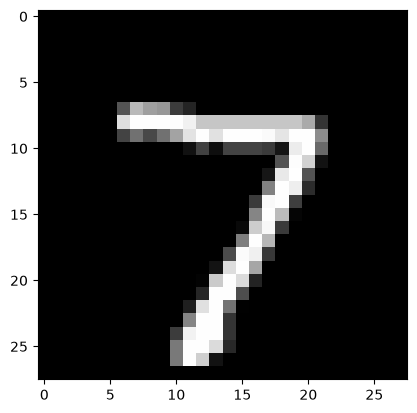

In [33]:
import matplotlib.pyplot as plt

id = 0

# display the selected image as a 28x28 grayscale plot
plt.imshow(x_test[id].reshape(28, 28), cmap='gray')
print('Label: ', y_test[id])

Define a fully connected neural network whose depth, individual layer widths, shared activation function, and Adam parameters can be tuned. Flatten each image into 784 values and use a 10 neuron softmax output layer.

In [34]:
from keras import models
from keras import layers
from keras import initializers
from keras import optimizers

def build_model(hp):
    # initialize a sequential model (linear stack of layers)
    model = models.Sequential()

    # total number of hidden layers (depth): 1, 2, or 3
    num_layers = hp.Int('num_layers', 1, 3)

    # apply one activation function to all hidden layers for the given trial
    activation = hp.Choice('activation', ['relu', 'tanh', 'sigmoid'])

    # flatten 28x28 image to 1D vector 784 values
    model.add(layers.Flatten())

    # tune the width of each hidden layer num_layer times and apply same activation function to all
    for i in range(num_layers):
        model.add(layers.Dense(
            # use a separate hyperparameter name to tune each hidden layer's width independently.
            units=hp.Int(f'layer_{i}_units', min_value=32, max_value=512, step=32),
            activation=activation
        ))

    # 10 neuron output layer with softmax for multi-class classification (digits 0-9)
    model.add(layers.Dense(10, activation='softmax'))

    # compile the model using adam optimizer with random hyperparameters to find ideal fit.
    # use categorical_crossentropy to measure difference between predicted probability and true label
    # use accuracy performance metric for % of correct predictions
    model.compile(
        optimizer=optimizers.Adam(
            # step size
            learning_rate=hp.Choice(
                'learning_rate',
                values=[1e-4, 1e-3, 1e-2]
            ),
            # exponential decay for momentum
            beta_1=hp.Choice(
                'beta_1',
                values=[0.7, 0.8, 0.9]
            ),
            # exponential decay for variance
            beta_2=hp.Choice(
                'beta_2',
                values=[0.95, 0.99, 0.999]
            )
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    # return un-trained, compiled hypermodel instance for the tuner to evaluate
    return model

Configure RandomSearch to try `MAX_TRIALS` hyperparameter combinations and select the combination with the highest validation accuracy. Set training to `EPOCHS` epochs with a batch size of `BATCH_SIZE`.

In [35]:
import keras_tuner

# configurations for searching and training
MAX_TRIALS = 20
EPOCHS = 20
BATCH_SIZE = 256

# configure RandomSearch to select the model with the highest vaidation accuracy
tuner = keras_tuner.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=MAX_TRIALS,
    overwrite=True,
    directory='hyperparameters',
    project_name='random_search_results'
)

# display the hyperparameter names and their possible values or ranges
tuner.search_space_summary()

Search space summary
Default search space size: 6
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh', 'sigmoid'], 'ordered': False}
layer_0_units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
beta_1 (Choice)
{'default': 0.7, 'conditions': [], 'values': [0.7, 0.8, 0.9], 'ordered': True}
beta_2 (Choice)
{'default': 0.95, 'conditions': [], 'values': [0.95, 0.99, 0.999], 'ordered': True}


Train the candidate models using the sub-training set and evaluate them using the validation set. The official test set is reserved for the final evaluation. We will track the model with the best `val_accuracy` for `MAX_TRIALS` trials. 

In [36]:
# run hyperparameter search across all trials
tuner.search(
    partial_x_train,
    partial_y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_valid, y_valid)
)

Trial 20 Complete [00h 00m 16s]
val_accuracy: 0.10970000177621841

Best val_accuracy So Far: 0.9739999771118164
Total elapsed time: 00h 08m 45s


Retrieve and print the best hyperparameter combination based on validation accuracy. Display the best model’s architecture and parameter counts.

In [37]:
# retrieve the best hyperparameter combination based on validation accuracy.
# get_best_hyperparameters returns a list of HyperParameter objects sorted from the best to the worst. We can use [0] to return the best hyperparamters.
best_hp = tuner.get_best_hyperparameters()[0]

# print the selected parameter names and values.
# To access the hyperparameters of the HyperParameter object, we use .values since it is a dictionary and we enumerate with .items()
print("Best Hyperparameters:")
for name, value in best_hp.values.items():
    print(f"{name}: {value}")

# retrieve the best trained model and display its architecture.
best_model = tuner.get_best_models()[0]
best_model.summary()

Best Hyperparameters:
num_layers: 2
activation: relu
layer_0_units: 256
learning_rate: 0.001
beta_1: 0.8
beta_2: 0.95
layer_1_units: 512
layer_2_units: 448


c:\Users\Brand\Documents\CSULB\CompSci\Classes\CECS458\Assignments\Assignment2\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337,674 (1.29 MB)

 Trainable params: 337,674 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

Build a fresh model using the selected hyperparameters and train it on the sub-training set. Record training and validation metrics in the history object for plotting.

In [38]:
# build a new, untrained model using the best hyperparameters.
final_model = tuner.hypermodel.build(best_hp)

# train the final model and record training and validation metrics returned in History object
history = final_model.fit(
    partial_x_train,
    partial_y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_valid, y_valid)
)

Epoch 1/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8737 - loss: 3.3852 - val_accuracy: 0.9291 - val_loss: 0.8233
Epoch 2/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9399 - loss: 0.5924 - val_accuracy: 0.9344 - val_loss: 0.6080
Epoch 3/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9571 - loss: 0.3500 - val_accuracy: 0.9556 - val_loss: 0.4424
Epoch 4/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9670 - loss: 0.2329 - val_accuracy: 0.9535 - val_loss: 0.3844
Epoch 5/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9729 - loss: 0.1727 - val_accuracy: 0.9541 - val_loss: 0.4431
Epoch 6/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9770 - loss: 0.1472 - val_accuracy: 0.9623 - val_loss: 0.3643
Epoch 7/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9805 - loss: 0.1135 - val_accuracy: 0.9577 - val_loss: 0.3990
Epoch 8/20
196/196 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9801 - loss: 0.1262 - val_accuracy: 0.

Plot training and validation loss across epochs to examine how the selected model learns and whether it shows signs of overfitting.

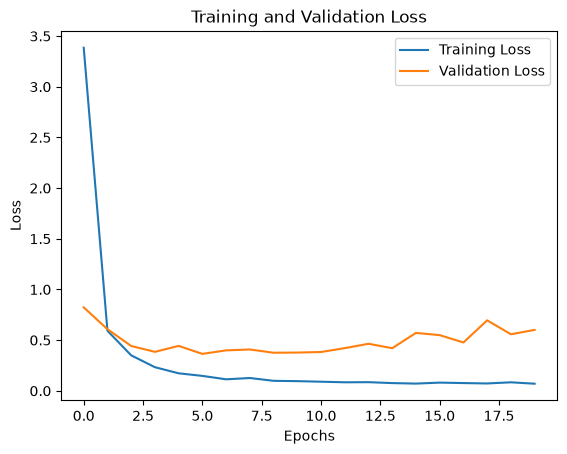

In [39]:
# plot training and validation losses recorded during final model training.
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

# pdd the title, axis labels, and legend.
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Evaluate the final model on the 10,000 official MNIST test images. Report its test loss and test accuracy.

In [41]:
# evaluate the final model on the test set without updating its weights.
# returns scalar test loss and test accuracy as configured in model.compile()
results = final_model.evaluate(x_test, y_test, batch_size=BATCH_SIZE)

# unpack and display the evaluation results
test_loss, test_accuracy = results
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9697 - loss: 0.5636
Test Loss:     0.5636
Test Accuracy: 96.97%
